In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [3]:
df = pd.read_excel('../data/metrics/P@K_new_virus/P@1.xlsx')

In [56]:
df[(df['virus'] == 'Egovirales_preproc') & (df['type'] == 'cross') & (df['model'] == model)]['mean_P@K'].values[0]

0.7422

In [65]:
pk_egov = {model: [] for model in df.model.unique()}
pk_mriya = {model: [] for model in df.model.unique()}

for i in range(1, 11):
    df = pd.read_excel(f'../data/metrics/P@K_new_virus/P@{i}.xlsx')
    for model in pk_egov:
        egov_val = df[(df['virus'] == 'Egovirales_preproc') & (df['type'] == 'forward') & (df['model'] == model)]['mean_P@K'].values[0]
        mriya_val = df[(df['virus'] == 'Mriyavirales_preproc') & (df['type'] == 'forward') & (df['model'] == model)]['mean_P@K'].values[0]
        pk_egov[model].append(egov_val)
        pk_mriya[model].append(mriya_val)

In [66]:
pk_egov = pd.DataFrame(pk_egov, index = np.arange(1, 11)).rename(columns = {'kmer': '4-mer'})
pk_mriya = pd.DataFrame(pk_mriya, index = np.arange(1, 11)).rename(columns = {'kmer': '4-mer'})

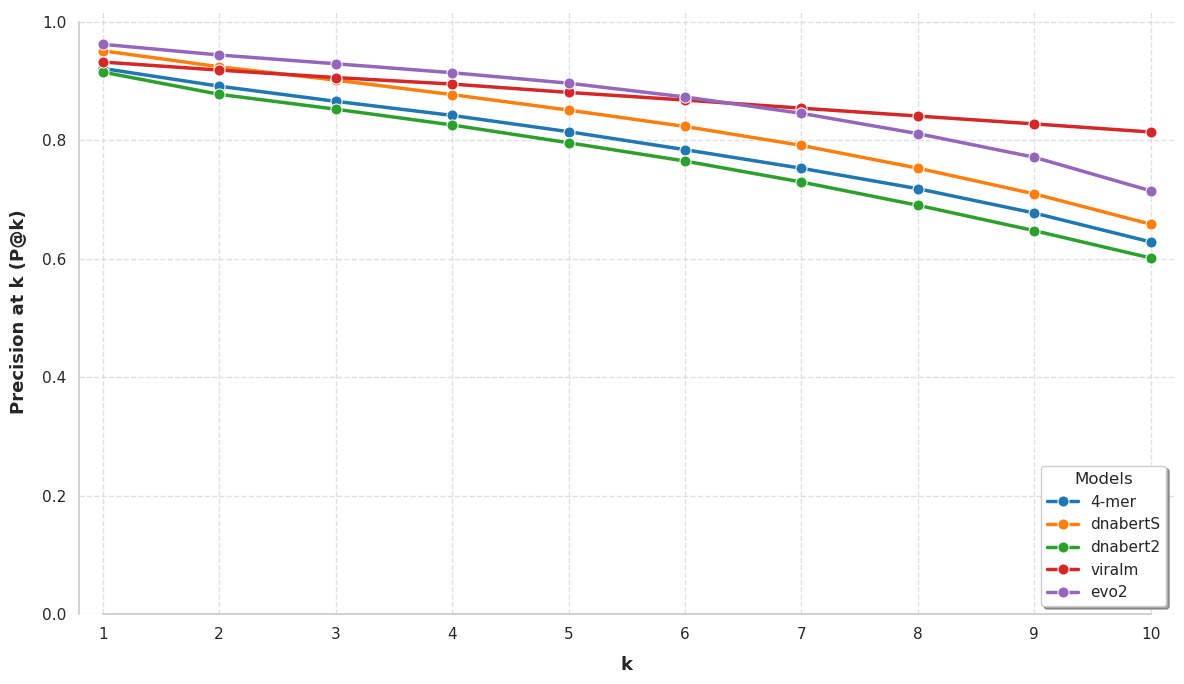

In [78]:
sns.set_theme(style="whitegrid", palette="tab10") 
plt.figure(figsize=(12, 7))

df_plot = pd.DataFrame(pk_egov, index=np.arange(1, 11))

ax = sns.lineplot(data=df_plot, dashes=False, linewidth=2.5, marker='o', markersize=8)

plt.xlabel('k', fontsize=13, fontweight='bold', labelpad=10)
plt.ylabel('Precision at k (P@k)', fontsize=13, fontweight='bold', labelpad=10)
plt.xticks(np.arange(1, 11))


plt.ylim(0.0, 1.02) 
plt.xlim(0.8, 10.2)
plt.grid(True, which='major', linestyle='--', alpha=0.6)

plt.legend(title='Models', title_fontsize='12', fontsize='11', 
           frameon=True, shadow=True, facecolor='white', loc='lower right')
sns.despine(trim=True)

plt.tight_layout()
plt.savefig('compare_metrics/for_article/Egovirales_k.png')
plt.show()

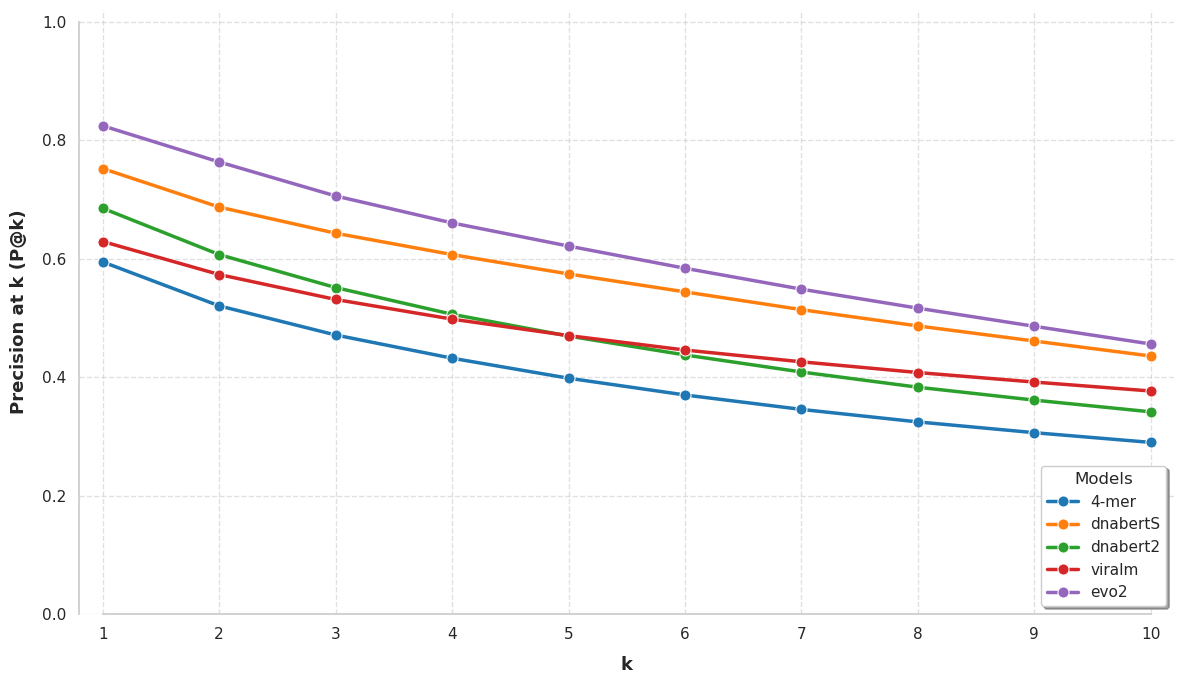

In [79]:
sns.set_theme(style="whitegrid", palette="tab10") 
plt.figure(figsize=(12, 7))

df_plot = pd.DataFrame(pk_mriya, index=np.arange(1, 11))

ax = sns.lineplot(data=df_plot, dashes=False, linewidth=2.5, marker='o', markersize=8)

plt.xlabel('k', fontsize=13, fontweight='bold', labelpad=10)
plt.ylabel('Precision at k (P@k)', fontsize=13, fontweight='bold', labelpad=10)
plt.xticks(np.arange(1, 11))

plt.ylim(0.0, 1.02)
plt.xlim(0.8, 10.2)
plt.grid(True, which='major', linestyle='--', alpha=0.6)

plt.legend(title='Models', title_fontsize='12', fontsize='11', 
           frameon=True, shadow=True, facecolor='white', loc='lower right')

sns.despine(trim=True)

plt.tight_layout()
plt.savefig('compare_metrics/for_article/Mriyavirales_k.png')
plt.show()